Árvore sem restrição - RMSE Treino: 0.0000, RMSE Teste: 0.6731
Gap de Generalização: 0.6731


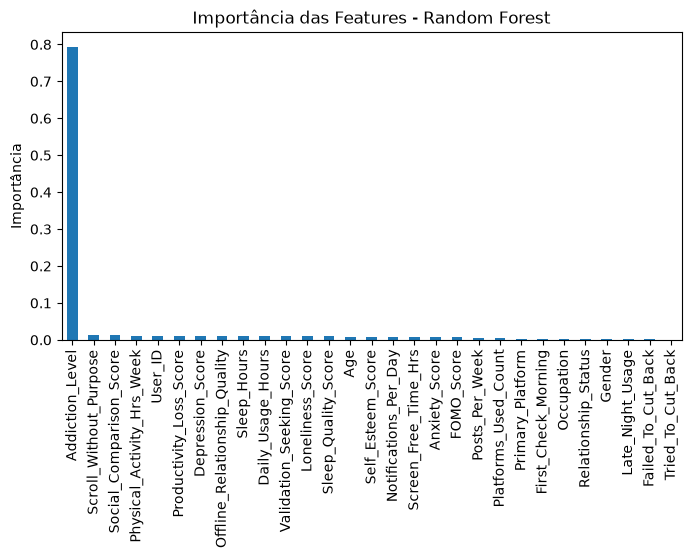

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

train_df = pd.read_csv('../data/processed/train_regression.csv')
test_df = pd.read_csv('../data/processed/test_regression.csv')
target_col = train_df.columns[-1]
X_train, y_train = train_df.drop(columns=[target_col]), train_df[target_col]
X_test, y_test = test_df.drop(columns=[target_col]), test_df[target_col]

dt_overfit = DecisionTreeRegressor(random_state=42)
dt_overfit.fit(X_train, y_train)

train_rmse = np.sqrt(mean_squared_error(y_train, dt_overfit.predict(X_train)))
test_rmse = np.sqrt(mean_squared_error(y_test, dt_overfit.predict(X_test)))

print(f"Árvore sem restrição - RMSE Treino: {train_rmse:.4f}, RMSE Teste: {test_rmse:.4f}")
print(f"Gap de Generalização: {test_rmse - train_rmse:.4f}")

rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
importances.plot(kind='bar')
plt.title("Importância das Features - Random Forest")
plt.ylabel("Importância")
plt.savefig('../reports/figures/feature_importances.png', bbox_inches='tight')
plt.show()